# Mixture Density Networks (MDNs) and Multinomial Neural Networks
This notebook demonstrates how to design a neural network architecture that handles mixture models and multinomial models using multiple layers and parallel activation functions.

In [11]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
from torch.distributions import Categorical, Normal
import torch.nn.functional as F

print(f"PyTorch version: {torch.__version__}")

PyTorch version: 2.15.0


## 1. Generate Non-Linear, Multi-Modal Data
Standard regression struggles with multi-valued functions (where one input $x$ maps to multiple possible outputs $y$). We create a classic inverted sinusoidal wave pattern.

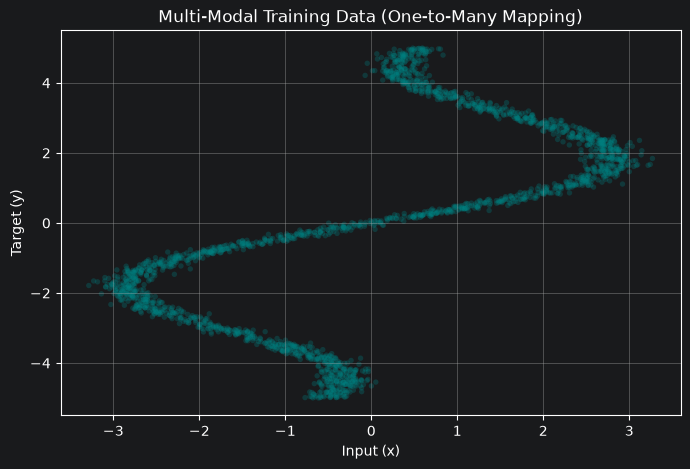

In [12]:
def generate_data(n_samples=2000):
    y = torch.rand(n_samples, 1) * 10 - 5
    # Multi-modal mapping: x = f(y) + noise
    x = y * 0.5 + torch.sin(y) * 2.0 + torch.randn(n_samples, 1) * 0.15
    return x, y

x_train, y_train = generate_data()
plt.figure(figsize=(8, 5))
plt.scatter(x_train.numpy(), y_train.numpy(), alpha=0.3, c='teal', edgecolors='none', s=15)
plt.title("Multi-Modal Training Data (One-to-Many Mapping)")
plt.xlabel("Input (x)")
plt.ylabel("Target (y)")
plt.grid(True)
plt.show()

## 2. Defining the Mixture Density Network Architecture
Our network uses standard `GELU` activations in hidden layers. The final layer splits into three parameter heads:
- **Pi (Weights):** Uses `Softmax` (probabilities sum to 1)
- **Mu (Means):** Uses `Linear` (unconstrained values)
- **Sigma (Variances):** Uses `Softplus` (strictly positive values $> 0$)

In [13]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class MixtureDensityNetwork(nn.Module):
    def __init__(self, input_dim=1, hidden_dim=64, num_components=3):
        super(MixtureDensityNetwork, self).__init__()
        self.num_components = num_components

        # Shared feature extraction hidden layers
        self.network = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.GELU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.GELU()
        )

        # Parallel heads map features to distribution parameters
        self.head_pi = nn.Linear(hidden_dim, num_components)
        self.head_mu = nn.Linear(hidden_dim, num_components)
        self.head_sigma = nn.Linear(hidden_dim, num_components)

    def forward(self, x):
        features = self.network(x)

        # Apply domain-specific activation functions safely
        pi = torch.softmax(self.head_pi(features), dim=-1)
        mu = self.head_mu(features)
        # Use F.softplus instead of torch.softplus
        sigma = F.softplus(self.head_sigma(features)) + 1e-4

        # This MUST return exactly three components
        return pi, mu, sigma

# Re-initialize the model to apply the fix
model = MixtureDensityNetwork(num_components=3)


## 3. Custom Negative Log-Likelihood (NLL) Loss Function

In [14]:
def mdn_loss_fn(pi, mu, sigma, y):
    # Evaluate probability density under each individual normal component
    normal_dist = Normal(mu, sigma)
    log_prob = normal_dist.log_prob(y.expand_as(mu))
    
    # Log-Sum-Exp trick handles stable computation of weighted sum log(sum(pi * N))
    weighted_log_prob = log_prob + torch.log(pi)
    loss = -torch.logsumexp(weighted_log_prob, dim=-1)
    return torch.mean(loss)

## 4. Model Training

In [15]:
optimizer = optim.Adam(model.parameters(), lr=0.005)
epochs = 600

for epoch in range(epochs):
    model.train()
    optimizer.zero_grad()
    
    pi, mu, sigma = model(x_train)
    loss = mdn_loss_fn(pi, mu, sigma, y_train)
    
    loss.backward()
    optimizer.step()
    
    if (epoch + 1) % 100 == 0:
        print(f"Epoch [{epoch+1}/{epochs}] - Loss: {loss.item():.4f}")

Epoch [100/600] - Loss: 1.5329
Epoch [200/600] - Loss: 1.4348
Epoch [300/600] - Loss: 1.3987
Epoch [400/600] - Loss: 1.3846
Epoch [500/600] - Loss: 1.3796
Epoch [600/600] - Loss: 1.3916


## 5. Sample from the Learned Conditional Mixture Model

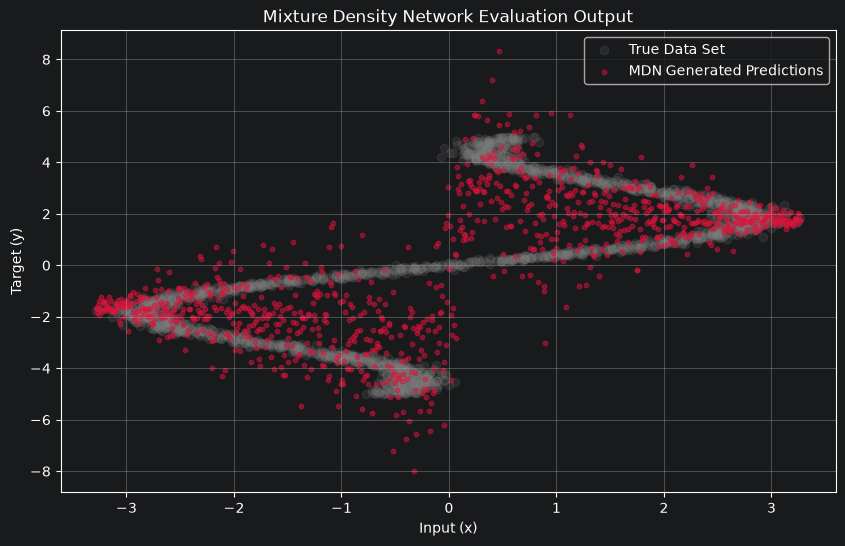

In [16]:
model.eval()
with torch.no_grad():
    # Generate testing inputs over the continuous horizon
    x_test = torch.linspace(x_train.min(), x_train.max(), 1000).view(-1, 1)
    pi, mu, sigma = model(x_test)
    
    # 1. Sample categorical component choice via Pi weights
    cat = Categorical(probs=pi)
    chosen_component = cat.sample()
    
    # 2. Extract corresponding mean and variance values
    sampled_mu = mu.gather(1, chosen_component.view(-1, 1)).squeeze()
    sampled_sigma = sigma.gather(1, chosen_component.view(-1, 1)).squeeze()
    
    # 3. Sample from selected Gaussian distribution
    y_samples = torch.normal(sampled_mu, sampled_sigma)

plt.figure(figsize=(10, 6))
plt.scatter(x_train.numpy(), y_train.numpy(), alpha=0.15, label="True Data Set", color='gray')
plt.scatter(x_test.numpy(), y_samples.numpy(), alpha=0.5, label="MDN Generated Predictions", color='crimson', s=10)
plt.title("Mixture Density Network Evaluation Output")
plt.xlabel("Input (x)")
plt.ylabel("Target (y)")
plt.legend()
plt.grid(True)
plt.show()